# Inteligencia Artificial
### Parte práctica de la primera prueba de evaluación alternativa. Curso 2024-25
### Grupo 2

In [ ]:
# Apellidos:
# Nombre:

A lo largo del examen, implementaremos algunas funciones relacionadas con algoritmos de planificación, con el fin último de poder resolver problemas de planificación de manera genérica.

Para ello, usaremos distintos problemas como ejemplo con el objetivo de verificar que, efectivamente, nuestro algoritmo resuelve de manera efectiva las instancias de dichos problemas. Un problema de búsqueda en espacio de estados viene definido por un estado inicial y un estado final, tal y como apareció en la práctica correspondiente.

Como se puede observar, las acciones están en un diccionario cuya clave es el nombre de la acción y el valor es un par ordenado donde la primera componente es el conjunto de precondiciones y la segunda es el conjunto de efectos. Los efectos y las precondiciones negativos están precedidos por el símbolo `-`.

Un ejemplo sería el problema de la rueda pinchada (en las diapositivas del Tema 3 de la asignatura), que a continuación se describe.

In [ ]:
acciones_rueda = {
    "quitar(rueda_pinchada,eje)" :
    ({"en(rueda_pinchada,eje)"},{"-en(rueda_pinchada,eje)", "en(rueda_pinchada,suelo)"}),
    "quitar(rueda_pinchada,maletero)" :
    ({"en(rueda_pinchada,maletero)"},{"-en(rueda_pinchada,maletero)", "en(rueda_pinchada,suelo)"}),
    "poner(rueda_pinchada,eje)" :
    ({"en(rueda_pinchada,suelo)", "-en(rueda_repuesto,eje)"},{"-en(rueda_pinchada,suelo)", "en(rueda_pinchada,eje)"}),
    "poner(rueda_pinchada,maletero)" :
    ({"en(rueda_pinchada,suelo)", "-en(rueda_repuesto,maletero)"},{"-en(rueda_pinchada,suelo)", "en(rueda_pinchada,maletero)"}),
    
    "quitar(rueda_repuesto,eje)" :
    ({"en(rueda_repuesto,eje)"},{"-en(rueda_repuesto,eje)", "en(rueda_repuesto,suelo)"}),
    "quitar(rueda_repuesto,maletero)" :
    ({"en(rueda_repuesto,maletero)"},{"-en(rueda_repuesto,maletero)", "en(rueda_repuesto,suelo)"}),
    "poner(rueda_repuesto,eje)" :
    ({"en(rueda_repuesto,suelo)", "-en(rueda_pinchada,eje)"},{"-en(rueda_repuesto,suelo)", "en(rueda_repuesto,eje)"}),
    "poner(rueda_pinchada,maletero)" :
    ({"en(rueda_repuesto,suelo)", "-en(rueda_pinchada,maletero)"},{"-en(rueda_repuesto,suelo)", "en(rueda_repuesto,maletero)"}),
    
    "dejarsolo()" :
    ({}, {"-en(rueda_pinchada,maletero)", "-en(rueda_pinchada,eje)", "-en(rueda_pinchada,suelo)", "-en(rueda_repuesto,maletero)", "-en(rueda_repuesto,eje)", "-en(rueda_repuesto,suelo)"})
}
estado_inicial_rueda = {"en(rueda_pinchada,eje)", "en(rueda_repuesto,maletero)"}
objetivo_rueda = {"en(rueda_repuesto,eje)"}

### Ejercicio 1 (0.5 ptos)
Defina las acciones, el estado inicial y el objetivo de los problemas que se describen a continuación tal y como se expresan en el problema de ejemplo. (**NOTA:** Usar letras mayúsculas tanto para los nombres de las acciones como para los átomos).

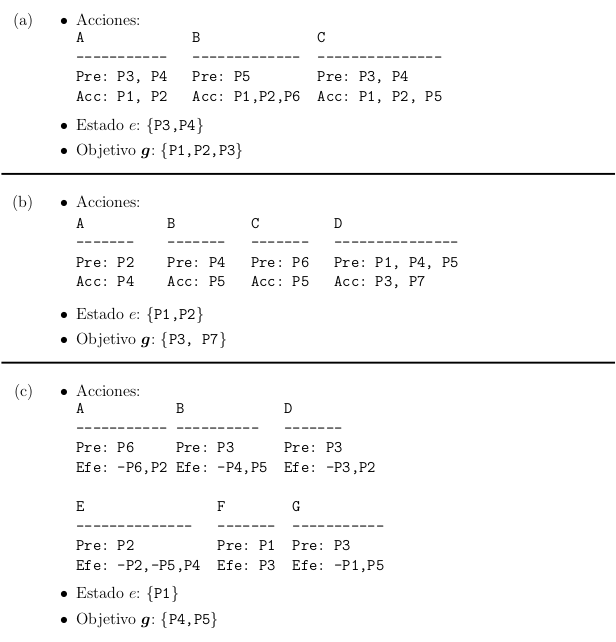

In [ ]:
# Solución
acciones_1 = 
estado_inicial_1 = 
objetivo_1 = 

acciones_2 = 
estado_inicial_2 = 
objetivo_2 = 

acciones_3 = 
estado_inicial_3 = 
objetivo_3 = 

Para diferenciar entre literales positivos y negativos, vamos a usar la función `es_negativo`, que devolverá `True`en caso de comenzar por el símbolo `-`. Además, también se proporciona la función `transforma_a_positivo` que le quitará el símbolo `-` al comienzo del literal si existiese, y lo dejará igual en cualquier otro caso.

In [ ]:
def es_negativo(literal):
    return literal.startswith('-')
def transforma_a_positivo(literal):
    if es_negativo(literal):
        return literal[1:]
    else:
        return literal

### Ejercicio 2 (1 pto)
Para usar los distintos algoritmos que se han estudiado, es imprescindible generalizar qué es un problema y, una vez definido, poder usar ese concepto para describir cualquier problema. Para ello, vamos a implementar la clase `Problema`, que será la base para cualquier problema que se pueda describir como problema de búsqueda en espacio de estados. El constructor de la clase tendrá que tener tres parámetros: `acciones`, que tendrá las acciones tal y como están descritas en el ejercicio anterior; `estado_inicial`, descrito como un conjunto de átomos; y `objetivo`, descrito como un conjunto de literales. `objetivo` será opcional y tendrá el conjunto vacío como valor por defecto. Además, esta clase tendrá que tener implementados tres métodos propios de la clase:
- `acciones_aplicables`: Tendrá como entrada un estado y devolverá un conjunto de acciones que se puedan ejecutar a partir del estado (es decir, que se cumplan las precondiciones, para lo que podemos usar, si es requerido, las funciones `es_negativo` y `transforma_a_positivo`, además de una función auxiliar implementada llamada `estado_cumple_precondiciones`).
- `aplica`: Recibe un estado y el nombre de una acción y devuelve el estado siguiente que se obtiene a partir de la aplicación de dicha acción al estado introducido.
- `es_estado_final`: Como entrada, recibirá un estado y comprobará si cumple con el objetivo **especificado en el problema** (es decir, el que se introduce en el constructor) y devolverá el valor Booleano correspondiente.

In [ ]:
# Solución
class Problema(object):
    
    def __init__(self, acciones, estado_inicial, objetivo=set()):
        pass

    def acciones_aplicables(self, estado):
        def estado_cumple_precondiciones(estado, precondiciones):
            return all([(not transforma_a_positivo(literal) in estado) if es_negativo(literal)
                        else (literal in estado) for literal in precondiciones])
        pass

    def aplica(self, estado, accion):
        pass
        

    def es_estado_final(self, estado):
        pass

Por ejemplo, si quisiéramos crear un problema específico con el problema de la rueda pinchada, se haría de la siguiente manera:

In [ ]:
class Problema_Rueda_Pinchada(Problema):

    def __init__(self):
        super().__init__(acciones_rueda, estado_inicial_rueda, objetivo_rueda)

In [ ]:
problema_rueda = Problema_Rueda_Pinchada()
problema_1 = Problema(acciones_1, estado_inicial_1, objetivo_1)
problema_2 = Problema(acciones_2, estado_inicial_2, objetivo_2)
problema_3 = Problema(acciones_3, estado_inicial_3, objetivo_3)

print(problema_rueda.acciones_aplicables(problema_rueda.estado_inicial))

for accion in problema_rueda.acciones_aplicables(problema_rueda.estado_inicial):
    print(problema_rueda.aplica(problema_rueda.estado_inicial, accion))

print(problema_rueda.es_estado_final(problema_rueda.estado_inicial))
print(problema_rueda.es_estado_final({"en(rueda_repuesto,eje)", "en(rueda_pinchada,maletero)"}))

# Resultado esperado:
#
# {'dejarsolo()', 'quitar(rueda_repuesto,maletero)', 'quitar(rueda_pinchada,eje)'}
# set()
# {'en(rueda_pinchada,eje)', 'en(rueda_repuesto,suelo)'}
# {'en(rueda_repuesto,maletero)', 'en(rueda_pinchada,suelo)'}
# False
# True

### Ejercicio 3 (0.25 ptos)
A continuación, pasaremos a describir el algoritmo de búsqueda en profundidad mediante heurísticas. El paso fundamental para este tipo de algoritmos es el orden en el que se analizan las posibles acciones a realizar. Para este paso vamos a crear una función `ordena_por_heuristica`, que recibe un estado (conjunto de átomos), una lista de acciones aplicables a dicho estado (lista de cadenas, que son los **nombres de las acciones**), un problema (una instancia de la clase `Problema`) y una función `h` que será la heurística por la que tendremos que ordenar la lista. Recordemos que el orden tiene que ser ascendente con respecto a la heurística; es decir, el primer elemento tendrá la heurística **más baja**.

**IMPORTANTE:** Una heurística recibirá como entrada tres parámetros:
- `estado`: El estado del cual queremos medir la heurística.
- `accion`: La acción que ha llevado desde el estado anterior al `estado` que se pasa por parámetros.
- `problema`: Una instancia de la clase `Problema`.

In [ ]:
# Solución

# Nota: si no ha conseguido implementar la función ordena_por_heuristica, puede descomentar
#       este código que devolverá la lista en el mismo orden en el que se ha proporcionado.
#       Esto es para que, en el ejercicio correspondiente, pueda al menos usar esta función.
#
# def ordena_por_heuristica(estado, aplicables, problema, h):
#     return aplicables

### Ejercicio 4 (0.25 ptos)
Vamos a comenzar definiendo una heurística trivial que hemos visto en clase, basada en el orden alfabético de las acciones. Es decir, la heurística tendrá que devolver un valor (puede ser numérico o no numérico, lo importante es que sea ordenable) que valga menos cuanto antes esté por orden alfabético. (**PISTA:** Para algunas heurísticas no es necesario usar los tres parámetros, por ejemplo, en esta solo tenemos que tener en cuenta el **nombre** de la acción. Intente comparar dos cadenas.)

In [ ]:
# Solución


In [ ]:
print(ordena_por_heuristica(problema_rueda.estado_inicial,
                            problema_rueda.acciones_aplicables(problema_rueda.estado_inicial),
                           problema_rueda,
                            heuristica_alfabetico))
print(ordena_por_heuristica(problema_1.estado_inicial,
                            problema_1.acciones_aplicables(problema_1.estado_inicial),
                           problema_1,
                            heuristica_alfabetico))
print(ordena_por_heuristica(problema_2.estado_inicial,
                            problema_2.acciones_aplicables(problema_2.estado_inicial),
                           problema_2,
                            heuristica_alfabetico))
print(ordena_por_heuristica(problema_3.estado_inicial,
                            problema_3.acciones_aplicables(problema_3.estado_inicial),
                           problema_3,
                            heuristica_alfabetico))

# Resultado esperado:
#
# ['dejarsolo()', 'quitar(rueda_pinchada,eje)', 'quitar(rueda_repuesto,maletero)']
# ['A', 'C']
# ['A']
# ['F']


### Ejercicio 5 (0.75 ptos)
Por fin, vamos implementar el algoritmo de búsqueda en profundidad. Para ello, usaremos una función auxiliar en la que implementaremos la recursividad tal y como aparece en las diapositivas de clase. La función `bep_h_rec` recibirá un plan parcial, una lista de estados visitados, el estado que se está analizando y una función de heurística.
- Si el estado actual cumple con el objetivo, se devolverá el plan.
- En cualquier otro caso, se creará la lista de acciones aplicables desde el estado actual y solo se tendrán en cuenta las acciones cuyos estados subsecuentes **no** estén en la listas de visitados.

In [ ]:
def busqueda_en_profundidad_h(problema, h):
    return bep_h_rec([], [problema.estado_inicial], problema.estado_inicial, problema, h)

In [ ]:
# Solución
def bep_h_rec(plan, visitados, actual, problema, h):
    if ?????????????????????????
        return ?????????????????????????
    else:
        aplicables = ?????????????????????????
        aplicables = [accion for accion in aplicables if not (problema.aplica(actual, accion) in visitados)]
        orden_aplicables = ?????????????????????????
        for ????????????????????????? in ?????????????????????????:
            estado_siguiente = ?????????????????????????
            res = ?????????????????????????
            if ?????????????????????????:
                return ?????????????????????????
        return ?????????????????????????

Para probar el funcionamiento del algoritmo, lo ejecutamos con los cuatro problemas como se describe a continuación:

In [ ]:
print(busqueda_en_profundidad_h(problema_rueda, heuristica_alfabetico))
print(busqueda_en_profundidad_h(problema_1, heuristica_alfabetico))
print(busqueda_en_profundidad_h(problema_2, heuristica_alfabetico))
print(busqueda_en_profundidad_h(problema_3, heuristica_alfabetico))

### Ejercicio 6 (0.75 ptos)
Por último, vamos a intentar mejorar el rendimiento con el uso de una heurística distinta de la que lleva el orden alfabético, como no, con la heurística $\Delta_0$. Para ello, vamos a seguir el siguiente comportamiento.
- La función principal será `heuristica_delta0`, que recibirá un estado, una acción y un problema (en este caso, la acción que ha llevado a este estado no es información relevante. Dicha función llamará a una función auxiliar `heuristica_delta0_aux` que será la encargada de realizar la función principal de nuestra heurística. Para ello, en la función principal **ya se proporciona** el primer sumatorio; es decir, si tenemos que obtener Δ0(e, {P1, P2, -P3}), lo que devuelve es Δ0(e, P1) + Δ0(e, P2) (con la función `sum`, como se puede observar).
La llamada a `heuristica_delta0_aux` se hace con dicho estado, con un átomo (en el ejemplo arriba descrito, las dos llamadas serían con `P1`y `P2`, respectivamente), un conjunto vacío y el problema objeto de estudio.
**A tener en cuenta:** Por supuesto, para calcular la heurística, tendremos que tener en cuenta las ideas fundamentales de la heurística $\Delta_0$ (que el átomo esté en en el estado, que el átomo sea efecto positivo en alguna de las acciones...). En la llamada recursiva, se elegirán solo las acciones que cumplan los dos criterios siguientes:
- Que tenga al átomo como efecto positivo; y
- Que no esté en la lista de visitados.

Este último requisito se impone para que no se dé un caso de recursión infinita.
Por lo demás, la definición de la función se hace de manera parecida a lo explicado en las diapositivas de la asignatura.

**NOTA:** Si se hace una llamada recursiva, se hará a la misma función `heuristica_delta0_aux`.

In [ ]:
def heuristica_delta0(estado, accion, problema):
    visitadas = set()
    return sum([heuristica_delta0_aux(estado, atomo, visitadas, problema) for atomo in problema.objetivo if not es_negativo(atomo)])

In [ ]:
# Solución
def heuristica_delta0_aux(estado, atomo, visitadas, problema):
    pass

In [ ]:
print(heuristica_delta0(problema_rueda.estado_inicial, "", problema_rueda))
print(heuristica_delta0(problema_1.estado_inicial, "", problema_1))
print(heuristica_delta0(problema_2.estado_inicial, "", problema_2))
print(heuristica_delta0(problema_3.estado_inicial, "", problema_3))

# Resultado esperado:
#
# 2
# 2
# 8
# 5

In [ ]:
print(busqueda_en_profundidad_h(problema_rueda, heuristica_delta0))
print(busqueda_en_profundidad_h(problema_1, heuristica_delta0))
print(busqueda_en_profundidad_h(problema_2, heuristica_delta0))
print(busqueda_en_profundidad_h(problema_3, heuristica_delta0))

# Resultado esperado:
#
# ['quitar(rueda_repuesto,maletero)', 'quitar(rueda_pinchada,eje)', 'poner(rueda_repuesto,eje)']
# ['C']
# ['A', 'B', 'D']
# ['F', 'B', 'D', 'F', 'E', 'G']